# Chapter 5 — Learning Multiple Weights at a Time: Generalizing Gradient Descent

*Grokking Deep Learning* · Andrew W. Trask · book pp. 79–98

Chapter 4 taught gradient descent on a network with **one** weight. This chapter shows that the *exact same recipe* carries over to networks with many inputs, many outputs, or both. The punchline: gradient descent is a general learning algorithm. If you can combine weights into a prediction and compute an error and a delta, it tells you how to move every weight.

| # | Section | Core idea |
|---|---------|-----------|
| 1 | Multiple inputs | One shared `delta`, one `weight_delta` per weight (`delta × that weight's input`) |
| 2 | Freezing a weight | Error is shared, so a frozen weight still sees error fall to 0, and a useful input can be ignored |
| 3 | Multiple outputs | One input, one `delta` per output, each multiplied by the same input |
| 4 | Multiple inputs *and* outputs | `weight_deltas` becomes an outer product (a whole matrix) |
| 5 | What do the weights learn? | Weights can be drawn as images; a dot product is a similarity score |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (6, 3.5)
plt.rcParams["axes.grid"] = True

---
## 1. Gradient descent with multiple inputs

### 1.1 The network and the data
Same toy data as chapter 3: for each game of the season we know the team's **average number of toes**, its **win/loss record**, and its **number of fans (millions)**. The target is whether the team won (`1`) or lost (`0`). The network is three inputs feeding one output through a weighted sum.

In [2]:
toes  = [8.5, 9.5, 9.9, 9.0]    # avg. number of toes per player
wlrec = [0.65, 0.8, 0.8, 0.9]   # win/loss record
nfans = [1.2, 1.3, 0.5, 1.0]    # fans, in millions
win_or_lose_binary = [1, 1, 0, 1]

init_weights = [0.1, 0.2, -0.1]

def w_sum(a, b):
    assert len(a) == len(b)
    return sum(x * y for x, y in zip(a, b))

def neural_network(input, weights):
    return w_sum(input, weights)

### 1.2 PREDICT + COMPARE
Nothing new here: predict, then compute `error` (squared, so it is always positive) and `delta` (signed: positive means "too high", negative means "too low").

In [3]:
input = [toes[0], wlrec[0], nfans[0]]      # first game of the season
true  = win_or_lose_binary[0]

pred  = neural_network(input, init_weights)
error = (pred - true) ** 2
delta = pred - true
print(f"pred={pred:.3f}   error={error:.4f}   delta={delta:.3f}")

pred=0.860   error=0.0196   delta=-0.140


### 1.3 LEARN — turning one `delta` into three `weight_delta`s
Here is the only real question of the section: the output node has **one** `delta`, but there are **three** weights. How does each weight get its own correction?

| Term | Meaning |
|------|---------|
| `delta` | How much higher or lower we want a *node's value* to be (`pred - true`). |
| `weight_delta` | A derivative-based estimate of how far and in which direction to move a *weight* to reduce that delta. |

The answer is `weight_delta = input × delta`, computed per weight. Each weight shares the same `delta` but has its own input, which gives you the same three properties you met in chapter 4:

* **Scaling** — a bigger input means the weight had more influence on the output, so it gets a bigger correction.
* **Negative reversal** — if the input is negative, raising the weight *lowers* the output, so the correction flips sign.
* **Stopping** — if the input is 0, the weight had no influence, so it is left alone.

In [4]:
def ele_mul(number, vector):
    return [number * v for v in vector]

weight_deltas = ele_mul(delta, input)
print("weight_deltas:", [round(w, 3) for w in weight_deltas])   # [-1.19, -0.091, -0.168]

# The three properties, shown on a single weight
alpha = 0.01
d = -0.14                                   # "predict a little higher"
for label, x in [("large positive input", 8.5), ("negative input", -8.5), ("zero input", 0.0)]:
    print(f"{label:22s} input={x:5.1f}   weight_delta={x*d + 0.0:7.3f}   weight change={-alpha*x*d:+.4f}")

weight_deltas: [-1.19, -0.091, -0.168]
large positive input   input=  8.5   weight_delta= -1.190   weight change=+0.0119
negative input         input= -8.5   weight_delta=  1.190   weight change=-0.0119
zero input             input=  0.0   weight_delta=  0.000   weight change=+0.0000


### 1.4 Update the weights
Multiply each `weight_delta` by `alpha` (to keep steps small and avoid overshooting) and subtract it from the weight.

In [5]:
weights = list(init_weights)
alpha = 0.01
for i in range(len(weights)):
    weights[i] -= alpha * weight_deltas[i]
print("new weights:", [round(w, 4) for w in weights])   # [0.1119, 0.2009, -0.0983]

new weights: [0.1119, 0.2009, -0.0983]


### 1.5 Watching several steps of learning
Let's wrap one full training step in a function and run it for a while, recording the error and every weight so we can plot what happens.

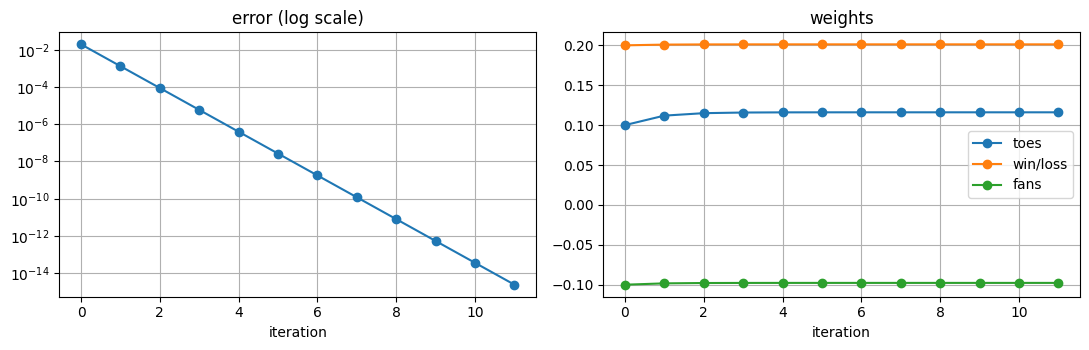

final weights: [ 0.1161  0.2012 -0.0977]  final error: 2.4001508278382324e-15


In [6]:
x = np.array([toes[0], wlrec[0], nfans[0]])
true = win_or_lose_binary[0]

def train_multi_input(alpha, iterations=40, w0=init_weights, frozen=()):
    # Gradient descent on one example. `frozen` lists weight indices to leave untouched.
    w = np.array(w0, dtype=float)
    err, ws = [], []
    for _ in range(iterations):
        pred = x.dot(w)
        delta = pred - true
        wd = delta * x
        for i in frozen:
            wd[i] = 0.0
        err.append(delta ** 2)
        ws.append(w.copy())
        w = w - alpha * wd
    return w, np.array(err), np.array(ws)

w_final, err, ws = train_multi_input(alpha=0.01, iterations=12)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(err, marker="o"); ax[0].set(title="error (log scale)", xlabel="iteration", yscale="log")
for i, name in enumerate(["toes", "win/loss", "fans"]):
    ax[1].plot(ws[:, i], marker="o", label=name)
ax[1].set(title="weights", xlabel="iteration"); ax[1].legend()
plt.tight_layout(); plt.show()
print("final weights:", w_final, " final error:", err[-1])

The `toes` weight does most of the moving. The reason is visible if we slice the error surface: hold two weights fixed, sweep the third, and plot the error. Every curve is a bowl, but the bowl for `toes` is far steeper because its input (8.5) is much larger than the others. Steepness equals the derivative, which is exactly what `weight_delta` measures.

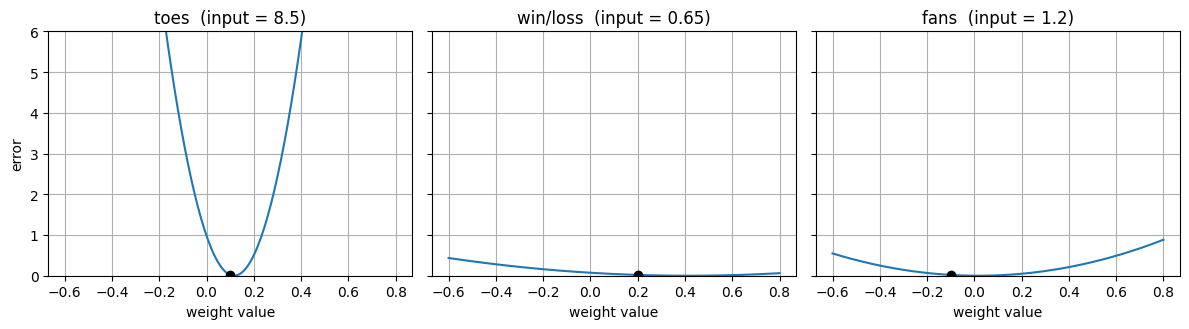

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
w0 = np.array(init_weights)
grid = np.linspace(-0.6, 0.8, 200)
for i, (ax, name) in enumerate(zip(axes, ["toes", "win/loss", "fans"])):
    errs = []
    for v in grid:
        w = w0.copy(); w[i] = v
        errs.append((x.dot(w) - true) ** 2)
    ax.plot(grid, errs)
    ax.scatter([w0[i]], [(x.dot(w0) - true) ** 2], color="k", zorder=3)
    ax.set(title=f"{name}  (input = {x[i]})", xlabel="weight value", ylim=(0, 6))
axes[0].set_ylabel("error")
plt.tight_layout(); plt.show()

### 1.6 Why `alpha` had to be small
Because the `toes` bowl is so steep, `alpha = 0.1` — which feels perfectly reasonable — makes the weight overshoot the bottom by more each step, and the error explodes. This is the divergence the book asks you to try. (A subfield called *normalization* exists partly to even out slopes like this.)

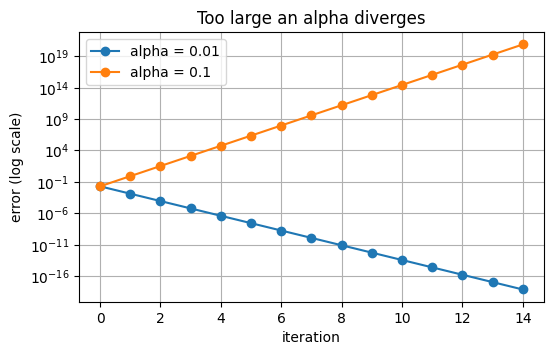

In [8]:
fig, ax = plt.subplots()
for a in (0.01, 0.1):
    _, e, _ = train_multi_input(alpha=a, iterations=15)
    ax.plot(e, marker="o", label=f"alpha = {a}")
ax.set(yscale="log", xlabel="iteration", ylabel="error (log scale)", title="Too large an alpha diverges")
ax.legend(); plt.show()

---
## 2. Freezing one weight: what does it do?

Experiment: never update the `toes` weight (set `weight_deltas[0] = 0`) and train with only the other two. The book uses `alpha = 0.3`, which is safe here because the steep weight is out of the picture.

weights after training: [ 0.1     0.2489 -0.0098]
toes weight unchanged : True
final error           : 3.993608332681372e-30


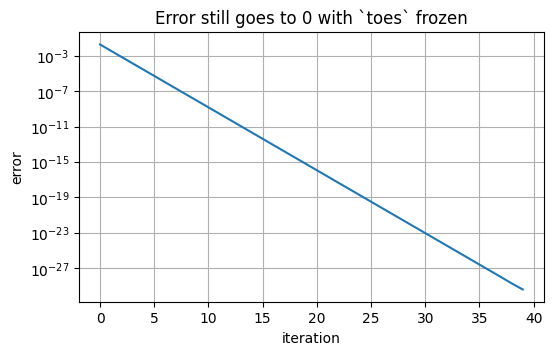

In [9]:
w_frozen, err_f, ws_f = train_multi_input(alpha=0.3, iterations=40, frozen=(0,))
print("weights after training:", w_frozen)
print("toes weight unchanged :", w_frozen[0] == init_weights[0])
print("final error           :", err_f[-1])

fig, ax = plt.subplots()
ax.plot(err_f); ax.set(yscale="log", xlabel="iteration", ylabel="error", title="Error still goes to 0 with `toes` frozen")
plt.show()

**Why does it still work?** Each weight's error curve measures that weight *against the shared global error*. When the other two weights drive the error to 0, the frozen weight's curve slides under its stationary dot and it "finds the bottom" too. In other words, the 2-D bowls are slices of a bigger shape: three weight axes plus one error axis (a 4-D **error plane**), whose curvature is fixed entirely by the training data. Training means finding the lowest point on that surface.

This has an uncomfortable consequence. Suppose the network has already reached error 0 without using `toes`. Then un-freeze `toes` and keep training:

In [10]:
# Start from the weights that already give error ≈ 0, now allow every weight to learn
w_after, err_after, ws_after = train_multi_input(alpha=0.01, iterations=200, w0=w_frozen)
print("toes weight before:", w_frozen[0], "  after 200 more iterations:", w_after[0])

toes weight before: 0.1   after 200 more iterations: 0.1000000000000001


It doesn't move: `error ≈ 0` means `delta ≈ 0`, which means every `weight_delta ≈ 0`. A powerful input can therefore be ignored forever simply because the network found *some other* way to fit the training data. Keep this in mind. It foreshadows overfitting in chapter 6.

---
## 3. Gradient descent with multiple outputs

Now flip the shape: **one input, three predictions**. From just the win/loss record we predict whether the team is *hurt*, whether they *win*, and whether they're *sad*. Each output has its own `error` and its own `delta`. Each weight's `weight_delta` is its output's delta times the (single, shared) input.

In [11]:
wlrec = [0.65, 1.0, 1.0, 0.9]
hurt  = [0.1, 0.0, 0.0, 0.1]
win   = [1, 1, 0, 1]
sad   = [0.1, 0.0, 0.1, 0.2]

w_out = np.array([0.3, 0.2, 0.9])        # one weight per output: hurt, win, sad
x_in  = wlrec[0]
target = np.array([hurt[0], win[0], sad[0]])

pred   = x_in * w_out
error  = (pred - target) ** 2
delta  = pred - target
weight_deltas = x_in * delta             # same input × each output's own delta

print("pred         :", pred)
print("delta        :", delta)
print("weight_deltas:", weight_deltas)

alpha = 0.1
print("new weights  :", w_out - alpha * weight_deltas)     # [0.294, 0.257, 0.868]

pred         : [0.195 0.13  0.585]
delta        : [ 0.095 -0.87   0.485]
weight_deltas: [ 0.0618 -0.5655  0.3153]
new weights  : [0.2938 0.2566 0.8685]


> **Note on the book's listing.** The printed code computes `weight_deltas = scalar_ele_mul(input, weights)`, which multiplies the input by the *weights*. The numbers in the accompanying diagram (0.062, −0.57, 0.315) actually come from multiplying the input by the **deltas**, which is also what the theory in this chapter says. The version above uses the deltas.

Train it for a while to confirm each output's error shrinks independently:

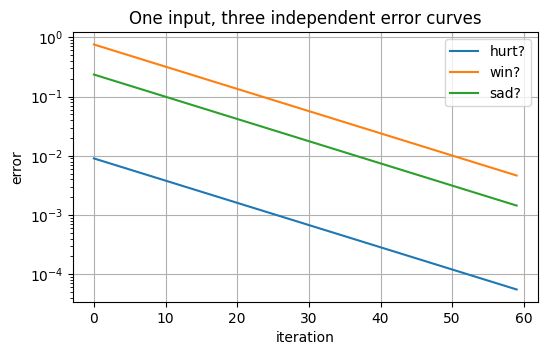

predictions: [0.1071 0.9347 0.1364]  targets: [0.1 1.  0.1]


In [12]:
w = np.array([0.3, 0.2, 0.9])
hist = []
for _ in range(60):
    p = x_in * w
    d = p - target
    hist.append(d ** 2)
    w = w - 0.1 * (x_in * d)
hist = np.array(hist)

fig, ax = plt.subplots()
for j, n in enumerate(["hurt?", "win?", "sad?"]):
    ax.plot(hist[:, j], label=n)
ax.set(yscale="log", xlabel="iteration", ylabel="error", title="One input, three independent error curves"); ax.legend()
plt.show()
print("predictions:", x_in * w, " targets:", target)

---
## 4. Gradient descent with multiple inputs *and* outputs

Combine both ideas: three inputs (`toes`, `win/loss`, `fans`) feed three outputs (`hurt?`, `win?`, `sad?`). The weights now form a **3 × 3 matrix**, and the prediction is a vector–matrix multiplication (a weighted sum per output).

The weight update follows the same rule as before — *for each weight, input × the delta of the output it feeds* — only now it applies to every (input, output) pair. That is exactly an **outer product** of the input vector and the delta vector, and the result has the same shape as the weight matrix.

> In the book the matrix is stored with one *row per output*. Here the matrix has one *column per output* (shape `inputs × outputs`) so that `x @ W` works directly; the numbers are the same.

In [13]:
toes  = [8.5, 9.5, 9.9, 9.0]
wlrec = [0.65, 0.8, 0.8, 0.9]
nfans = [1.2, 1.3, 0.5, 1.0]

W = np.array([[0.1, 0.1, -0.3],     # weights into "hurt?"
              [0.1, 0.2,  0.0],     # weights into "win?"
              [0.0, 1.3,  0.1]]).T  # weights into "sad?"   -> shape (3 inputs, 3 outputs)

x = np.array([toes[0], wlrec[0], nfans[0]])
target = np.array([hurt[0], win[0], sad[0]])

pred   = x.dot(W)
error  = (pred - target) ** 2
delta  = pred - target
weight_deltas = np.outer(x, delta)        # (3,) ⊗ (3,) -> (3, 3)

print("pred :", pred)             # [0.555 0.98  0.965]
print("error:", error)            # [0.207 0.0004 0.748]
print("weight_deltas (rows = inputs, cols = outputs):")
print(weight_deltas)

pred : [0.555 0.98  0.965]
error: [0.207  0.0004 0.7482]
weight_deltas (rows = inputs, cols = outputs):
[[ 3.8675 -0.17    7.3525]
 [ 0.2958 -0.013   0.5623]
 [ 0.546  -0.024   1.038 ]]


In [14]:
alpha = 0.01
W_new = W - alpha * weight_deltas
print("W before:\n", W, "\nW after one step:\n", W_new)

# Train for a while
W_t = W.copy()
errs = []
for _ in range(200):
    p = x.dot(W_t)
    d = p - target
    errs.append((d ** 2).sum())
    W_t -= alpha * np.outer(x, d)
print("\nfinal predictions:", x.dot(W_t), " targets:", target)

W before:
 [[ 0.1  0.1  0. ]
 [ 0.1  0.2  1.3]
 [-0.3  0.   0.1]] 
W after one step:
 [[ 0.0613  0.1017 -0.0735]
 [ 0.097   0.2001  1.2944]
 [-0.3055  0.0002  0.0896]]

final predictions: [0.1 1.  0.1]  targets: [0.1 1.  0.1]


---
## 5. What do these weights learn?

The book now moves to a real dataset: **MNIST**, 28 × 28 greyscale images of handwritten digits. The image is flattened into a vector of 784 pixels, so the network is the same multi-input/multi-output design with **784 inputs** and **10 outputs** (one score per digit). The output we want for an image of a "2" is `1.0` in the third slot and `0` elsewhere.

> **About the data here.** The book loads MNIST through a separate preprocessing notebook. To keep this notebook runnable offline, I use scikit-learn's bundled **8 × 8 digits** dataset instead (64 inputs, 10 outputs). The code is otherwise identical; swap in the 784-pixel MNIST arrays and nothing else changes.

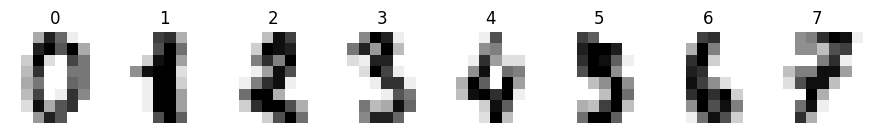

inputs per example: 64 | outputs: 10


In [15]:
from sklearn.datasets import load_digits

digits = load_digits()
X_all = digits.data / 16.0                 # pixels scaled to 0..1
y_all = digits.target
Y_all = np.eye(10)[y_all]                  # one-hot targets

X_tr, Y_tr, y_tr = X_all[:1000], Y_all[:1000], y_all[:1000]
X_te, y_te       = X_all[1000:], y_all[1000:]

fig, axes = plt.subplots(1, 8, figsize=(11, 1.8))
for ax, img, lab in zip(axes, digits.images[:8], y_all[:8]):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.show()
print("inputs per example:", X_tr.shape[1], "| outputs:", Y_tr.shape[1])

train accuracy = 95.1%   test accuracy = 89.1%


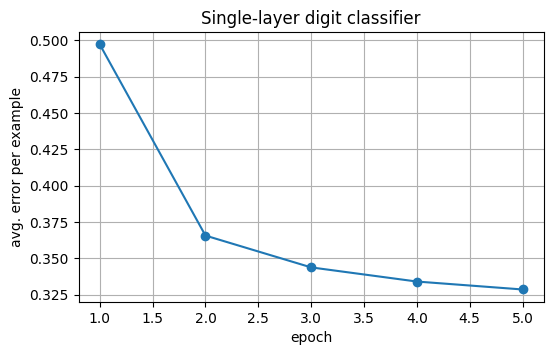

In [16]:
W = np.zeros((64, 10))
alpha = 0.01
curve = []

for epoch in range(5):
    total = 0.0
    for x_i, t_i in zip(X_tr, Y_tr):          # stochastic: one example at a time
        d = x_i.dot(W) - t_i
        total += (d ** 2).sum()
        W -= alpha * np.outer(x_i, d)
    curve.append(total / len(X_tr))

acc_tr = (X_tr.dot(W).argmax(1) == y_tr).mean()
acc_te = (X_te.dot(W).argmax(1) == y_te).mean()
print(f"train accuracy = {acc_tr:.1%}   test accuracy = {acc_te:.1%}")

fig, ax = plt.subplots()
ax.plot(range(1, 6), curve, marker="o"); ax.set(xlabel="epoch", ylabel="avg. error per example", title="Single-layer digit classifier")
plt.show()

### 5.1 Visualizing weight values
Each output node has one weight per pixel. A high weight says "this pixel correlates with my digit"; a negative weight says "this pixel counts *against* my digit". If we reshape those weights back to the image shape, we can see what each node looks for.

On 28 × 28 MNIST the book shows vaguely recognizable 2s and 1s. With only 64 pixels the pictures are rougher, so the second row below adds a sanity check: *the average image of each digit minus the average of all digits*. If the weights really encode "which pixels correlate with this digit", the two rows should resemble each other, and the printed correlations say they do.

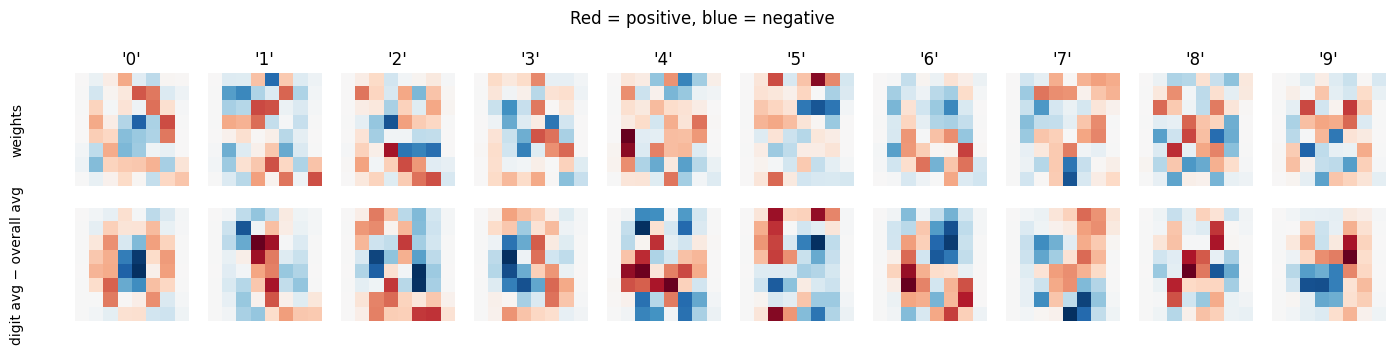

correlation between each weight map and its digit's deviation image: [0.71 0.61 0.64 0.71 0.61 0.78 0.74 0.68 0.81 0.65]


In [17]:
mean_all = X_tr.mean(axis=0)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
m = np.abs(W).max()
corrs = []
for k in range(10):
    dev = X_tr[y_tr == k].mean(axis=0) - mean_all
    corrs.append(np.corrcoef(W[:, k], dev)[0, 1])
    axes[0, k].imshow(W[:, k].reshape(8, 8), cmap="RdBu_r", vmin=-m, vmax=m)
    axes[1, k].imshow(dev.reshape(8, 8), cmap="RdBu_r", vmin=-np.abs(dev).max(), vmax=np.abs(dev).max())
    axes[0, k].set_title(f"'{k}'"); axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].text(-0.45, 0.5, "weights", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.45, 0.5, "digit avg − overall avg", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Red = positive, blue = negative", y=1.02)
plt.tight_layout(); plt.show()
print("correlation between each weight map and its digit's deviation image:", np.round(corrs, 2))

### 5.2 Why it looks that way: dot products as similarity
The prediction for each output is a **dot product** between the image and that node's weights: multiply element-wise, then sum. Where both vectors are positive at the same positions the sum is large; where they have nothing in common it is 0. So a dot product is a loose **similarity measure**, and learning shapes each weight vector until it resembles the pattern of its digit.

In [18]:
a = np.array([0, 1, 0, 1]);   b = np.array([1, 0, 1, 0])
c = np.array([0, 1, 1, 0]);   d = np.array([.5, 0, .5, 0])

print("a · b =", a.dot(b), "   (nothing in common)")
print("c · d =", c.dot(d), "  (one overlapping position)")
print("c · b =", c.dot(b))
print("c · c =", c.dot(c), "   (identical vectors score highest)")

# The same idea on a real digit: its score under each output node
img = X_te[0]
scores = img.dot(W)
print("\ntrue label:", y_te[0], "| scores per digit:", scores.round(2), "| prediction:", scores.argmax())

a · b = 0    (nothing in common)
c · d = 0.5   (one overlapping position)
c · b = 1
c · c = 2    (identical vectors score highest)

true label: 1 | scores per digit: [ 0.04  0.77  0.19  0.3  -0.1  -0.22  0.06 -0.06 -0.01 -0.14] | prediction: 1
